# **1. Análisis Exploratorio de Datos (EDA)**  
## ✨ PREPARACIÓN DE LOS DATOS

---

**🔶 CARGAR LOS DATOS QUE YA HEMOS GENERADO ANTERIORMENTE**

In [18]:
import pandas as pd

clientes = pd.read_csv(r"C:\Users\Dell\Desktop\BOOTCAMP_DATA\ESPECIALIZACIÓN\S13_PROYECTO\BBDD SINTETICAS 2021-2025\clientes.csv")
reservas = pd.read_csv(r"C:\Users\Dell\Desktop\BOOTCAMP_DATA\ESPECIALIZACIÓN\S13_PROYECTO\BBDD SINTETICAS 2021-2025\reservas_flash_2021_2025.csv")

reservas["fecha_reserva"] = pd.to_datetime(reservas["fecha_reserva"])  # convertir a fecha
reservas["fecha_salida"] = pd.to_datetime(reservas["fecha_salida"])
reservas["fecha_vuelta"] = pd.to_datetime(reservas["fecha_salida"])

**🔶 COMPROBAMOS LOS DATOS**

In [19]:
display(clientes.head(5))
display(clientes.describe())
display(clientes.dtypes)

,id_cliente,edad,sexo,comunidad
0,CLT-000001,58,M,Castilla y León
1,CLT-000002,19,F,Navarra
2,CLT-000003,33,M,Comunitat Valenciana
3,CLT-000004,26,M,Cataluña
4,CLT-000005,61,M,Andalucía


,edad
count,34684.000000
mean,46.624351
std,16.710584
min,18.000000
25%,32.000000
50%,47.000000
75%,61.000000
max,75.000000


id_cliente      str
edad          int64
sexo            str
comunidad       str
dtype: object

In [20]:
display(reservas.head(5))
display(reservas.dtypes)

,fecha_reserva,id_reserva,proveedor,precio_bruto,importe,comision,descuento_real,fecha_salida,fecha_vuelta,numero_noches,...,adultos,niños,bebes,destino,pais_destino,categoria_viaje,id_cliente,edad_cliente,sexo_cliente,comunidad_autonoma_cliente
0,2021-01-01,2021-000001,Samatravel,"393,98","319,12","38,29","19,00 %",2021-03-18,2021-03-18,8,...,1,1,0,San Sebastián,España,camping,CLT-002703,62,M,Andalucía
1,2021-01-01,2021-000002,Bambara Travel,"333,84","257,06","30,85","23,00 %",2021-03-26,2021-03-26,4,...,3,1,0,Madrid,España,camping,CLT-002619,58,M,Andalucía
2,2021-01-01,2021-000003,Nomada,"1470,58","1235,29","148,23","16,00 %",2021-05-16,2021-05-16,10,...,1,1,1,Lisboa,Portugal,solo hotel,CLT-002657,38,M,Castilla y León
3,2021-01-01,2021-000004,Viajes Olympia,"82,94","72,16","8,66","13,00 %",2021-05-29,2021-05-29,2,...,2,0,1,Cáceres,España,camping,CLT-002667,61,M,Andalucía
4,2021-01-01,2021-000005,Sidertours,"238,29","181,1","21,73","24,00 %",2021-02-21,2021-02-21,2,...,2,1,1,Benidorm,España,solo hotel,CLT-002670,18,F,Andalucía


fecha_reserva                 datetime64[us]
id_reserva                               str
proveedor                                str
precio_bruto                             str
importe                                  str
comision                                 str
descuento_real                           str
fecha_salida                  datetime64[us]
fecha_vuelta                  datetime64[us]
numero_noches                          int64
tipo_habitacion                          str
numero_habitaciones                    int64
numero_viajeros_total                  int64
adultos                                int64
niños                                  int64
bebes                                  int64
destino                                  str
pais_destino                             str
categoria_viaje                          str
id_cliente                               str
edad_cliente                           int64
sexo_cliente                             str
comunidad_

In [21]:
columnas = ["precio_bruto", "importe", "comision", "descuento_real"]

for col in columnas:
    reservas[col] = pd.to_numeric(
        reservas[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.replace(",", ".", regex=False)
        .str.strip(),
        errors="coerce"
    )

print(reservas[columnas].describe())
print(reservas[columnas].isna().sum())

       precio_bruto       importe      comision  descuento_real
count  64119.000000  64119.000000  64119.000000    64119.000000
mean    1522.353455   1255.306559    150.636785       17.523948
std     1656.465466   1368.306125    164.196734        4.350294
min       17.330000     13.940000      1.670000       10.000000
25%      273.980000    225.195000     27.025000       14.000000
50%      831.490000    684.780000     82.170000       18.000000
75%     2351.865000   1935.155000    232.220000       21.000000
max     8768.000000   6576.000000    789.120000       25.000000
precio_bruto      0
importe           0
comision          0
descuento_real    0
dtype: int64


In [22]:
print(reservas[columnas].describe())
print(reservas[columnas].isna().sum())

       precio_bruto       importe      comision  descuento_real
count  64119.000000  64119.000000  64119.000000    64119.000000
mean    1522.353455   1255.306559    150.636785       17.523948
std     1656.465466   1368.306125    164.196734        4.350294
min       17.330000     13.940000      1.670000       10.000000
25%      273.980000    225.195000     27.025000       14.000000
50%      831.490000    684.780000     82.170000       18.000000
75%     2351.865000   1935.155000    232.220000       21.000000
max     8768.000000   6576.000000    789.120000       25.000000
precio_bruto      0
importe           0
comision          0
descuento_real    0
dtype: int64


In [23]:
display(reservas.dtypes)

fecha_reserva                 datetime64[us]
id_reserva                               str
proveedor                                str
precio_bruto                         float64
importe                              float64
comision                             float64
descuento_real                       float64
fecha_salida                  datetime64[us]
fecha_vuelta                  datetime64[us]
numero_noches                          int64
tipo_habitacion                          str
numero_habitaciones                    int64
numero_viajeros_total                  int64
adultos                                int64
niños                                  int64
bebes                                  int64
destino                                  str
pais_destino                             str
categoria_viaje                          str
id_cliente                               str
edad_cliente                           int64
sexo_cliente                             str
comunidad_

In [24]:
display(reservas.describe())

,fecha_reserva,precio_bruto,importe,comision,descuento_real,fecha_salida,fecha_vuelta,numero_noches,numero_habitaciones,numero_viajeros_total,adultos,niños,bebes,edad_cliente
count,64119,64119.000000,64119.000000,64119.000000,64119.000000,64119,64119,64119.000000,64119.000000,64119.000000,64119.000000,64119.000000,64119.000000,64119.000000
mean,2023-07-31 05:51:02.686567,1522.353455,1255.306559,150.636785,17.523948,2023-10-05 06:10:14.794367,2023-10-05 06:10:14.794367,6.212324,2.002729,3.503813,2.004149,0.999782,0.499883,46.669271
min,2021-01-01 00:00:00,17.330000,13.940000,1.670000,10.000000,2021-01-20 00:00:00,2021-01-20 00:00:00,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,18.000000
25%,2022-06-13 00:00:00,273.980000,225.195000,27.025000,14.000000,2022-07-26 00:00:00,2022-07-26 00:00:00,3.000000,2.000000,3.000000,1.000000,0.000000,0.000000,32.000000
50%,2023-07-13 00:00:00,831.490000,684.780000,82.170000,18.000000,2023-08-19 00:00:00,2023-08-19 00:00:00,7.000000,2.000000,4.000000,2.000000,1.000000,0.000000,47.000000
75%,2024-09-21 00:00:00,2351.865000,1935.155000,232.220000,21.000000,2024-12-11 00:00:00,2024-12-11 00:00:00,9.000000,2.000000,4.000000,3.000000,2.000000,1.000000,61.000000
max,2025-12-31 00:00:00,8768.000000,6576.000000,789.120000,25.000000,2026-06-29 00:00:00,2026-06-29 00:00:00,14.000000,3.000000,6.000000,3.000000,2.000000,1.000000,75.000000
std,NaN,1656.465466,1368.306125,164.196734,4.350294,NaN,NaN,3.916132,0.669697,1.266525,0.816340,0.816751,0.500004,16.687677


⚡ No veo valores atípicos. El rango entre el importe *max* y *min* es muy amplio pero es habitual ➡ reservas de corta duración vs larga estancia.

In [25]:
reservas["importe"].value_counts().head(10)

importe
6576.00    240
6260.16     23
6558.74     21
6326.36     16
6220.30     16
6429.83     16
6384.06     15
6451.39     15
6479.46     14
6418.53     11
Name: count, dtype: int64

⚡Hay un importe que acumula muchas más reservas en comparación con el resto: 6576€. Podremos verlo, es posible que sea un "Best Seller" de precio cerrado.

In [26]:
print(clientes.isnull().sum())
print(reservas.isnull().sum())
print("Duplicados en id_reserva:", reservas["id_reserva"].duplicated().sum())
print("Duplicados en id_cliente (clientes):", clientes["id_cliente"].duplicated().sum())

id_cliente    0
edad          0
sexo          0
comunidad     0
dtype: int64
fecha_reserva                 0
id_reserva                    0
proveedor                     0
precio_bruto                  0
importe                       0
comision                      0
descuento_real                0
fecha_salida                  0
fecha_vuelta                  0
numero_noches                 0
tipo_habitacion               0
numero_habitaciones           0
numero_viajeros_total         0
adultos                       0
niños                         0
bebes                         0
destino                       0
pais_destino                  0
categoria_viaje               0
id_cliente                    0
edad_cliente                  0
sexo_cliente                  0
comunidad_autonoma_cliente    0
dtype: int64
Duplicados en id_reserva: 0
Duplicados en id_cliente (clientes): 0


⚡No hay duplicados, pero es normal porque el dataset lo he creado yo.

---

**🔹Comprobamos que los clientes coinciden**

Es decir, veamos si la información en sexo y edad de la tabla clientes coincide con la misma info que tenemos en la tabla de reservas.

In [27]:
# comparamos edad y sexo entre las dos tablas
check_clientes = reservas[["id_cliente","edad_cliente","sexo_cliente"]].drop_duplicates(subset="id_cliente")
check_clientes = check_clientes.merge(clientes[["id_cliente","edad","sexo"]], on="id_cliente", how="left")

error_edad = check_clientes[check_clientes["edad_cliente"] != check_clientes["edad"]]
error_sexo = check_clientes[check_clientes["sexo_cliente"] != check_clientes["sexo"]]

print(f"Clientes con edad distinta entre tablas: {len(error_edad)}")
print(f"Clientes con sexo distinto entre tablas: {len(error_sexo)}")

Clientes con edad distinta entre tablas: 0
Clientes con sexo distinto entre tablas: 0


In [28]:
print(clientes.isnull().sum())
print(reservas.isnull().sum())
print("Duplicados en id_reserva:", reservas["id_reserva"].duplicated().sum())
print("Duplicados en id_cliente (clientes):", clientes["id_cliente"].duplicated().sum())

id_cliente    0
edad          0
sexo          0
comunidad     0
dtype: int64
fecha_reserva                 0
id_reserva                    0
proveedor                     0
precio_bruto                  0
importe                       0
comision                      0
descuento_real                0
fecha_salida                  0
fecha_vuelta                  0
numero_noches                 0
tipo_habitacion               0
numero_habitaciones           0
numero_viajeros_total         0
adultos                       0
niños                         0
bebes                         0
destino                       0
pais_destino                  0
categoria_viaje               0
id_cliente                    0
edad_cliente                  0
sexo_cliente                  0
comunidad_autonoma_cliente    0
dtype: int64
Duplicados en id_reserva: 0
Duplicados en id_cliente (clientes): 0


**🔶 OUTLIERS**

Comprobamos las variables numéricas para detectar valores incongruentes.

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

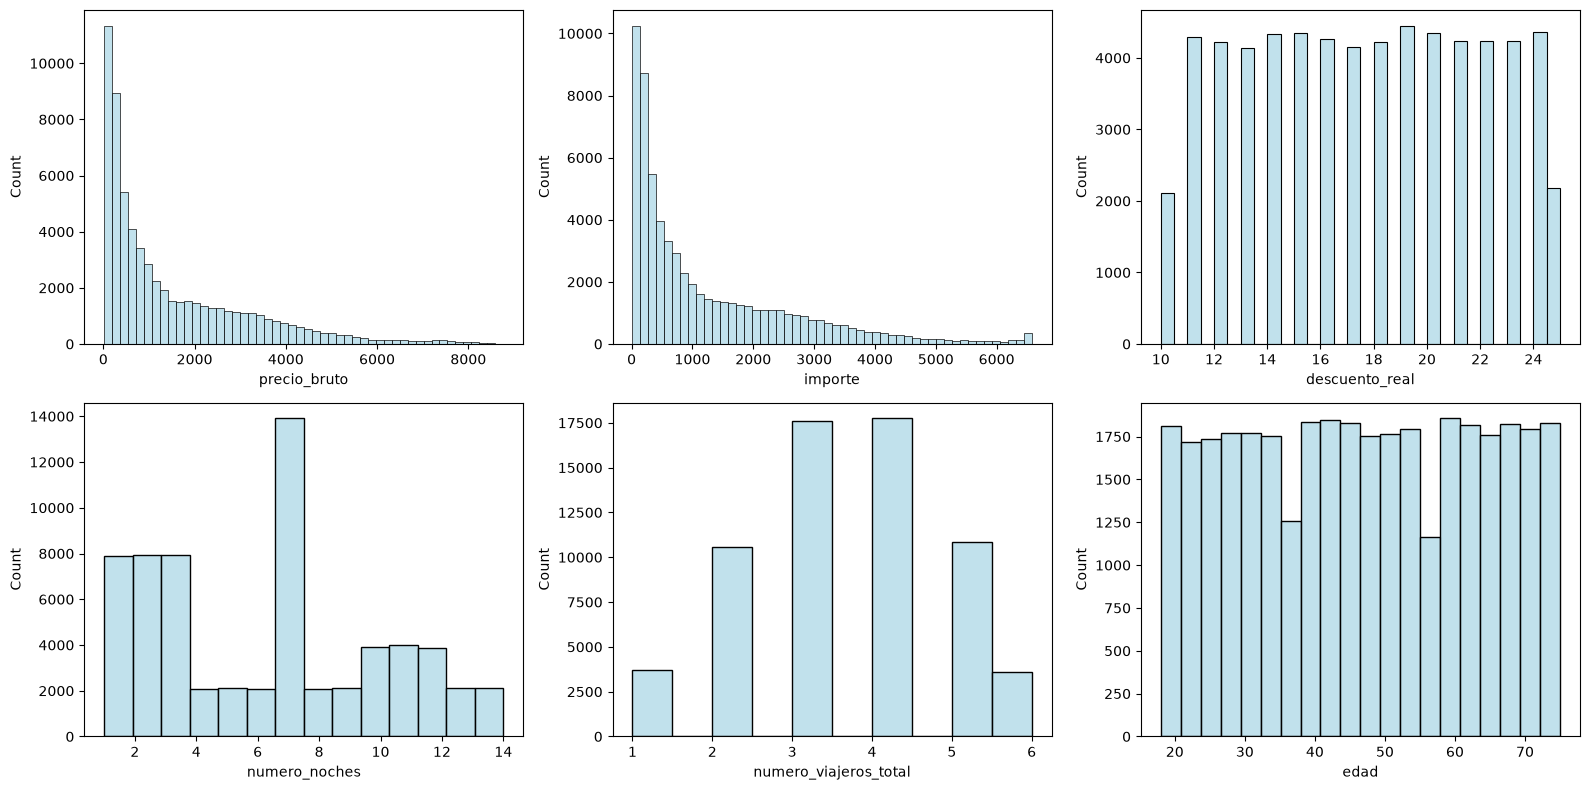

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(16,8))
sns.histplot(reservas["precio_bruto"], bins=50, ax=axes[0,0], color="lightblue")
sns.histplot(reservas["importe"], bins=50, ax=axes[0,1], color="lightblue")
sns.histplot(reservas["descuento_real"], bins=30, ax=axes[0,2], color="lightblue")
sns.histplot(reservas["numero_noches"], bins=14, ax=axes[1,0], color="lightblue")
sns.histplot(reservas["numero_viajeros_total"], bins=10, ax=axes[1,1], color="lightblue")
sns.histplot(clientes["edad"], bins=20, ax=axes[1,2], color="lightblue")
plt.tight_layout()
plt.show()

**⚡ GRÁFICO 1 - precio_bruto** La cantidad de importes bajos se ajusta a la demanda de los españoles y a la concentración de reservas de corta estancia.

**⚡ GRÁFICO 2 - importe** Muy relacionado con el PVP del producto pero cambia según comisiones y descuentos de cada venta.

**⚡ GRÁFICO 3 - descuento_real** Se mantiene estable, es decir, no fluctua mucho. El descuento más alto y más bajo tiene menos frecuencia, algo habitual en la venta flash. Los descuento deben ser atractivos: un 10% no lo es y un 24% es mucho para asumir por una empresa si incluimos nuestra comisión.

**⚡ GRÁFICO 4 - numero_noches** 1, 2 y 3 noches es una escapada estándar, por ejemplo, fines de semana. 4 a 6 noches es menos habitual. 7 noches corresponde al pequete de Egipto que genera grandes ventas y a semanas completas que pueden hacer referencia a verano. Resto no destacan pero son grandes viajes.  

**⚡ GRÁFICO 5 - numero_viajeros_total** Viajes "singles" son menos habituales aunque cada vez ganan más terreno. De 2 a 4 noches suelen ser viajes de parejas o familias 2 ad + 2 niños o bebés. Bastante correcta la distribución.

**⚡ GRÁFICO 6 - edad** Tenemos clientes de todas la edades. Más tarde, si interesa, podremos analizar el por qué de la caida antes de los 40 y de los 60.

---

**💠 Médodo IQR:** 

Utilizaré el método IQR (Rango Intercuartílico) para medir la dispersión de mi conjunto de datos y detectar valores atípicos, si los hubiera.

In [31]:
Q1 = reservas["precio_bruto"].quantile(0.25)
Q3 = reservas["precio_bruto"].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5*IQR
limite_superior = Q3 + 1.5*IQR

outliers = reservas[(reservas["precio_bruto"] < limite_inferior) | (reservas["precio_bruto"] > limite_superior)]
print(f"Límites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Outliers: {len(outliers)} ({len(outliers)/len(reservas)*100:.2f}%)")


outliers = reservas[(reservas["precio_bruto"] < limite_inferior) | (reservas["precio_bruto"] > limite_superior)]

Límites: [-2842.85, 5468.69]
Outliers: 2155 (3.36%)


In [32]:
print("Outliers por debajo:", (reservas["precio_bruto"] < limite_inferior).sum())
print("Outliers por encima:", (reservas["precio_bruto"] > limite_superior).sum())
print(outliers["pais_destino"].value_counts().head(10))

Outliers por debajo: 0
Outliers por encima: 2155
pais_destino
Japón        1687
Egipto        160
España        111
Tailandia      52
EEUU           50
Vietnam        31
Indonesia      23
Noruega        13
Cuba            6
Italia          5
Name: count, dtype: int64


In [33]:
pct_japon_sobre_outliers = (outliers["pais_destino"]=="Japón").sum() / len(outliers) * 100
print(f"{pct_japon_sobre_outliers:.1f}%")

78.3%


⚡ Utilizando el **método IQR** hemos podido detectar un total de 2.155 *outliers* (3,36%) en precio_bruto. De éstos, el 78,3% corressponde a destinos de larga distancia (Japón), lo cual puede ser normal, son viajes de alto importe y de larga estancia que sobresalen del importe más habitual.

**💠 Comprobamos el pico de ventas de 7 noches:**

In [34]:
noches7 = reservas[reservas["numero_noches"]==7]
print(f"Total reservas de 7 noches: {len(noches7)} ({len(noches7)/len(reservas)*100:.1f}%)")
print("\n")
print(noches7["pais_destino"].value_counts().head(10))
print("\n")
print(noches7["categoria_viaje"].value_counts())
print("\n")
print(noches7["destino"].value_counts().head(10))

Total reservas de 7 noches: 13907 (21.7%)


pais_destino
Egipto       11316
España        1946
Noruega        221
Jordania       112
Cuba           101
Italia          38
Tailandia       27
EEUU            25
Francia         19
Vietnam         17
Name: count, dtype: int64


categoria_viaje
crucero             11316
solo hotel           1056
camping              1020
viaje organizado      515
Name: count, dtype: int64


destino
Hurghada                  5615
El Cairo                  5593
Bilbao                     121
Granada                    114
Fiordos Noruegos           114
Circuito Jordania          112
Crucero por El Nilo        108
Laponia                    107
Santiago de Compostela     105
Málaga                     104
Name: count, dtype: int64


⚡ Vemos que el pico de 7 noches coincide con el "Best Seller" Egipto, que es un crucero empaquetado. El resto se divide en los siguientes paquetes de 7 noches (viajes organizados) y algunas reservas de España.

# **2. COMPORTAMIENTO DEL CLIENTE**
## ✨ ANÁLISIS DE COHORTES

Medir si los clientes vuelven a comprar, y cuándo dejan de hacerlo.

**🔶 CALCULAR LA PRIMERA COMPRA**

In [35]:
# fecha de primera compra por cliente, agrupamos por id del cliente
primera_compra = reservas.groupby("id_cliente")["fecha_reserva"].min().reset_index()
primera_compra.columns = ["id_cliente", "fecha_primera_compra"]
primera_compra["mes_cohorte"] = primera_compra["fecha_primera_compra"].dt.to_period("M")

display(primera_compra.head())

primera_compra.to_csv("primera_compra.csv", index=False, encoding="utf-8-sig")
print(f"Nº de clientes con al menos 1 compra: {len(primera_compra)}")
print(f"Nº de clientes en la tabla clientes: {len(clientes)}")

clientes_sin_compra = len(clientes) - len(primera_compra)

print(f"Nº de clientes que nunca han comprado: {clientes_sin_compra}")

,id_cliente,fecha_primera_compra,mes_cohorte
0,CLT-000001,2021-06-30,2021-06
1,CLT-000002,2021-07-15,2021-07
2,CLT-000003,2021-11-19,2021-11
3,CLT-000004,2021-06-08,2021-06
4,CLT-000005,2021-11-24,2021-11


Nº de clientes con al menos 1 compra: 34684
Nº de clientes en la tabla clientes: 34684
Nº de clientes que nunca han comprado: 0


In [36]:
clientes_sin_compra = len(clientes) - len(primera_compra)
pct_sin_compra = clientes_sin_compra / len(clientes) * 100

print(f"Clientes sin compra: {pct_sin_compra:.1f}%")

Clientes sin compra: 0.0%


**📌 Nota importante:** No tenemos ningún cliente sin compra porque el dataset lo he creado yo. En la realidad podría analizarse, al tratarse de un *site* privado, los clientes se registran para comprar una oferta en concreto y puede que luego nunca vuelvan.

---

**💠 CALCULAR EL MES DE DESFASE**

Debemos saber cuántos meses han pasado entre la primera compra de un cliente y una reserva cualquiera del mismo cliente (teniendo en cuenta siempre su mes 0 = mes de primera compra)

In [37]:
reservas_coh = reservas.merge(primera_compra[["id_cliente","mes_cohorte"]], on="id_cliente", how="left")
reservas_coh["mes_reserva"] = reservas_coh["fecha_reserva"].dt.to_period("M")
reservas_coh["desfase_meses"] = (reservas_coh["mes_reserva"] - reservas_coh["mes_cohorte"]).apply(lambda x: x.n)

display(reservas_coh[["id_cliente","mes_cohorte","mes_reserva","desfase_meses"]].head(10))
print(reservas_coh["desfase_meses"].describe())

,id_cliente,mes_cohorte,mes_reserva,desfase_meses
0,CLT-002703,2021-01,2021-01,0
1,CLT-002619,2021-01,2021-01,0
2,CLT-002657,2021-01,2021-01,0
3,CLT-002667,2021-01,2021-01,0
4,CLT-002670,2021-01,2021-01,0
5,CLT-002098,2021-01,2021-01,0
6,CLT-002720,2021-01,2021-01,0
7,CLT-002728,2021-01,2021-01,0
8,CLT-002740,2021-01,2021-01,0
9,CLT-002750,2021-01,2021-01,0


count    64119.000000
mean         8.196416
std         12.603062
min          0.000000
25%          0.000000
50%          0.000000
75%         13.000000
max         59.000000
Name: desfase_meses, dtype: float64


**🎯 RESULTADO:**
+ El ***mínimo*** es 0 ya que cada cliente tiene su mes de desfase en 0 en su primera compra.
+ El ***máximo*** es 59 puede ser correcto ya que un cliente que compró por primera vez en enero de 2021 puede tener siguiente compra en 2025 y pasar 59 meses (5 años = 60 meses).
+ Con la ***mediana*** en 0 y el ***percentil 75*** en 13 podemos ver que hay meses de desfase altos, interesante para este estudio.

---

**💠 COHORTES Y CLIENTES ACTIVOS**

Necesitamos contar cuántos clientes activos (clientes que han realizado al menos una compra) que hay por cohorte y por mes de desfase. Los agrupamos cuando coinciden en mes_cohorte y desfase de meses. Deben ser clientes únicos.

🚩 Primero el 100% habran comprado en su propio mes 0. Debemos no contar con ellos. Lo voy a tomar como referencia para calcular el % de los demas cohortes.


In [38]:
# clientes con reserva (clientes activos) por cohorte y desfase
activos = reservas_coh.groupby(["mes_cohorte","desfase_meses"])["id_cliente"].nunique().reset_index(name="clientes_activos")

# tamaño de cada cohorte = clientes activos en desfase 0
tamano_cohorte = activos[activos["desfase_meses"]==0][["mes_cohorte","clientes_activos"]].rename(columns={"clientes_activos":"tamano_cohorte"})

cohortes = activos.merge(tamano_cohorte, on="mes_cohorte")
cohortes["retencion_pct"] = (cohortes["clientes_activos"] / cohortes["tamano_cohorte"] * 100).round(2)

display(cohortes.head(20))
cohortes.to_csv("cohortes.csv", index=False, encoding="utf-8-sig")

,mes_cohorte,desfase_meses,clientes_activos,tamano_cohorte,retencion_pct
0,2021-01,0,573,573,100.00
1,2021-01,1,29,573,5.06
2,2021-01,2,20,573,3.49
3,2021-01,3,14,573,2.44
4,2021-01,4,16,573,2.79
5,2021-01,5,14,573,2.44
6,2021-01,6,15,573,2.62
7,2021-01,7,16,573,2.79
8,2021-01,8,12,573,2.09
9,2021-01,9,13,573,2.27


⚡El porcentaje de retención se mantiene bastante estable con una ligera subida en el mes 11 y 12. Aunque no es un hecho probado, puede deberse a volver a reservar las vacaciones de la primera compra? vacaciones anuales?

En un gráfico de lineas podré ver si hay realmente estos picos cada 12 meses desde la primera compra.

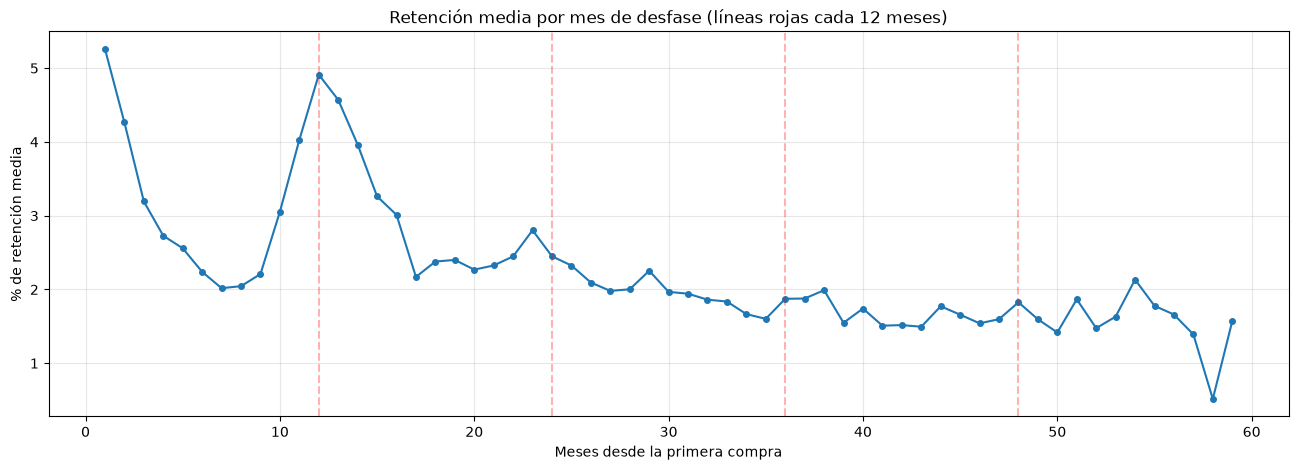

In [39]:
tabla_segmentos_finales_completo = cohortes.groupby("desfase_meses")["retencion_pct"].mean()

plt.figure(figsize=(16,5))
tabla_segmentos_finales_completo.loc[1:].plot(marker="o", markersize=4)
for x in [12, 24, 36, 48]:
    plt.axvline(x, color="red", linestyle="--", alpha=0.3)
plt.title("Retención media por mes de desfase (líneas rojas cada 12 meses)")
plt.xlabel("Meses desde la primera compra")
plt.ylabel("% de retención media")
plt.grid(alpha=0.3)
plt.show()

**🎯 CONCLUSIONES:** 

Vemos unos pequeños picos en el mes 12 y 24, aunque el del mes 36 ya es más débil pero todavía visible, y a partir del mes 40 el número de cohortes cae en picado.

Observamos, entonces, un patrón de recurrencia anual: picos de retención en los meses 12, 24 y, de forma más ligera, el mes 36 tras la primera compra que puede indicarnos un patrón de compra de vacaciones anuales. El patrón pierde fiabilidad estadística a partir del mes 40, pero podría ser normal ya que el dataset abarca solo 5 años asi que no podemos ver la retención mas allá de estos datos. 

**📌 Nota importante:** En la estrategia de marketing, tener en cuenta un estos datos, "vacaciones anuales".

---

# ✨ SEGMENTACIÓN Y CLUSTERING

**🔶 CALCULAR RFM (Recencia, Frecuencia y Valor Monetario) DEL CLIENTE**

+ ¿Cuánto tiempo ha pasado desde su última compra?
+  ¿Con qué regularidad compra?
+  ¿Cuánto dinero ha gastado en total?


In [40]:
FECHA_CORTE = pd.Timestamp("2025-12-31") # no pongo la fecha de hoy, pongamos que en un análisis para una empresa evaluando los últimos 5 años. Por lo tanto, tomo como referencia la fecha del fin del dataset

rfm = reservas.groupby("id_cliente").agg(
    ultima_compra=("fecha_reserva", "max"),
    frecuencia=("id_reserva", "count"),
    valor_monetario=("importe", "sum")
).reset_index()

rfm["recencia_dias"] = (FECHA_CORTE - rfm["ultima_compra"]).dt.days

display(rfm.head())
display(rfm.describe())
rfm.to_csv("RFM.csv", index=False, encoding="utf-8-sig")

,id_cliente,ultima_compra,frecuencia,valor_monetario,recencia_dias
0,CLT-000001,2021-07-10,2,363.19,1635
1,CLT-000002,2025-04-23,4,3324.88,252
2,CLT-000003,2021-11-19,1,109.07,1503
3,CLT-000004,2025-09-28,5,4357.10,94
4,CLT-000005,2021-11-24,1,1616.11,1498


,ultima_compra,frecuencia,valor_monetario,recencia_dias
count,34684,34684.000000,34684.000000,34684.000000
mean,2023-09-21 22:38:25.062853,1.848662,2320.637794,831.056654
min,2021-01-01 00:00:00,1.000000,14.140000,0.000000
25%,2022-06-11 00:00:00,1.000000,379.855000,276.000000
50%,2023-08-17 00:00:00,1.000000,1353.325000,867.000000
75%,2025-03-30 00:00:00,2.000000,3198.780000,1299.000000
max,2025-12-31 00:00:00,15.000000,23612.730000,1825.000000
std,NaN,1.576821,2769.569375,546.235843


En la tabla estadística vemos que no hay valores anormales, determinamos que entre los clientes hay un máximo de 15 compras y el mínimo de 1, ya sabiamos que todos los clientes habían hecho al menos una compra. 


Entre el *Q3* y el *máx* hay una gran diferencia, lo cual nos indica que hay muchos valores bajos, muchos clientes con pocas compras.

---

Voy a crear y guardar 2 tablas:
+ 1 tabla de frecuencias con valores totales, el numero de clientes que han efectuado X compras.
+ 1 tabla de frecuencias en porcentajes, para saber cómo afecta al total de las compras. 

In [41]:
dist_frecuencia = rfm["frecuencia"].value_counts().sort_index().reset_index()
display(dist_frecuencia.head(15))
dist_frecuencia.to_csv("frecuencia_compra.csv", index=False, encoding="utf-8-sig")

,frecuencia,count
0,1,22042
1,2,6199
2,3,2408
3,4,1383
4,5,969
5,6,701
6,7,453
7,8,264
8,9,143
9,10,67


In [42]:
tabla_frecuencia = rfm["frecuencia"].value_counts().sort_index().reset_index()
tabla_frecuencia.columns = ["numero_compras", "numero_clientes"]

tabla_frecuencia["pct_clientes"] = (tabla_frecuencia["numero_clientes"] / len(rfm) * 100).round(2)
tabla_frecuencia["pct_acumulado"] = tabla_frecuencia["pct_clientes"].cumsum().round(2)

display(tabla_frecuencia)
tabla_frecuencia.to_csv("tabla_frecuencia.csv", index=False, encoding="utf-8-sig")

,numero_compras,numero_clientes,pct_clientes,pct_acumulado
0,1,22042,63.55,63.55
1,2,6199,17.87,81.42
2,3,2408,6.94,88.36
3,4,1383,3.99,92.35
4,5,969,2.79,95.14
5,6,701,2.02,97.16
6,7,453,1.31,98.47
7,8,264,0.76,99.23
8,9,143,0.41,99.64
9,10,67,0.19,99.83


**💠 CALCULAR LAS PUNTUACIONES R, F Y M**

+ PUNTUACIÓN RECENCIA: Vamos a dividir a los clientes en 5 grupos dándoles una puntuación del 1 al 5 (siendo el 5 el mejor cliente, HACE MENOS TIEMPO QUE HIZO SU ÚLTIMA COMPRA).
+ PUNTUACIÓN FRECUENCIA: Dividimos de nuevo en 5 grupos, pero ordenamos por orden de aparición, hay muchos clientes con una sola compra, luego tendremos que forzar la distribución.
+ PUNTUACIÓN VALOR MONETARIO: De nuevo dividimos en 5 grupo por el importe total de todas sus compras.

+ PUNTUACIÓN TOTAL - RFM: sumamos los valores (cada una de las puntuaciones RFM) de cada cliente, el peor cliente tendrá una puntuación de 3 (R=1, F=1, M=1) y un máximos de 15. Asi establecemos una puntuación para cada cliente que luego nos servirá para definir una estrategia.

Lo guardamos en la tabla y la exportamos para tener estos datos.

In [43]:
rfm["punt_recencia"] = pd.qcut(rfm["recencia_dias"], 5, labels=[5,4,3,2,1]).astype(int)  # ordenar y dividir en 5 grupos
rfm["punt_frecuencia"] = pd.qcut(rfm["frecuencia"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)  # ordenar y dividir en 5 grupos
rfm["punt_valor_monetario"] = pd.qcut(rfm["valor_monetario"], 5, labels=[1,2,3,4,5]).astype(int)  # ordenar y dividir en 5 grupos

rfm["punt_RFM"] = rfm["punt_recencia"] + rfm["punt_frecuencia"] + rfm["punt_valor_monetario"]

display(rfm[["id_cliente","ultima_compra","recencia_dias","punt_recencia","frecuencia","punt_frecuencia","valor_monetario","punt_valor_monetario","punt_RFM"]].head(10))
rfm.to_csv("RFM.csv", index=False, encoding="utf-8-sig")

,id_cliente,ultima_compra,recencia_dias,punt_recencia,frecuencia,punt_frecuencia,valor_monetario,punt_valor_monetario,punt_RFM
0,CLT-000001,2021-07-10,1635,1,2,4,363.19,2,7
1,CLT-000002,2025-04-23,252,4,4,5,3324.88,4,13
2,CLT-000003,2021-11-19,1503,1,1,1,109.07,1,3
3,CLT-000004,2025-09-28,94,5,5,5,4357.10,5,15
4,CLT-000005,2021-11-24,1498,1,1,1,1616.11,3,5
5,CLT-000006,2021-03-01,1766,1,1,1,340.35,2,4
6,CLT-000007,2024-02-15,685,3,4,5,10860.14,5,13
7,CLT-000008,2022-10-12,1176,2,2,4,133.79,1,7
8,CLT-000009,2024-04-20,620,3,3,5,5913.21,5,13
9,CLT-000010,2025-05-20,225,4,6,5,3938.88,5,14


**🚩 Problema:** como he mostrado antes, el 65% de los clientes tienen una sola compra, por lo tanto, al hacer la división en 5 puntuaciones de clientes, muchos clientes con 1 sola compra se repartirán en diferentes quintiles. Esto supone un problema, como hay un máximo de 15 compras, voy a forzar manualmente esta puntuación. 

In [44]:
def asignar_punt_frecuencia(frecuencia):
    if frecuencia == 1:
        return 1
    elif frecuencia == 2:
        return 2
    elif frecuencia == 3:
        return 3
    elif frecuencia == 4:
        return 4
    else:
        return 5

rfm["punt_frecuencia"] = rfm["frecuencia"].apply(asignar_punt_frecuencia)

Recalculamos la puntuación total

In [45]:
rfm["punt_RFM"] = rfm["punt_recencia"] + rfm["punt_frecuencia"] + rfm["punt_valor_monetario"]

In [46]:
display(rfm)

,id_cliente,ultima_compra,frecuencia,valor_monetario,recencia_dias,punt_recencia,punt_frecuencia,punt_valor_monetario,punt_RFM
0,CLT-000001,2021-07-10,2,363.19,1635,1,2,2,5
1,CLT-000002,2025-04-23,4,3324.88,252,4,4,4,12
2,CLT-000003,2021-11-19,1,109.07,1503,1,1,1,3
3,CLT-000004,2025-09-28,5,4357.10,94,5,5,5,15
4,CLT-000005,2021-11-24,1,1616.11,1498,1,1,3,5
...,...,...,...,...,...,...,...,...,...
34679,CLT-034680,2025-12-08,1,4021.30,23,5,1,5,11
34680,CLT-034681,2025-12-13,1,3423.64,18,5,1,4,10
34681,CLT-034682,2025-12-14,1,58.96,17,5,1,1,7
34682,CLT-034683,2025-12-03,1,6200.92,28,5,1,5,11


In [47]:
print(rfm.groupby("punt_recencia")["recencia_dias"].agg(["min","max","count"]))
print()
print(rfm.groupby("punt_valor_monetario")["valor_monetario"].agg(["min","max","count"]))

                min   max  count
punt_recencia                   
1              1385  1825   6933
2              1004  1384   6931
3               586  1003   6935
4               215   585   6930
5                 0   214   6955

                          min       max  count
punt_valor_monetario                          
1                       14.14    279.65   6938
2                      279.69    844.87   6936
3                      844.96   2004.59   6936
4                     2004.60   3751.30   6937
5                     3751.47  23612.73   6937


**💠 SEGMENTAR - PONERLE NOMBRE A LOS SEGMENTOS** 

**... y por lo tanto al tipo de cliente.**

Según la puntuación de cada cliente, determinaremos en qué grupo se encuentran: si son clientes recurrentes o que hace tiempo que no compran, por ejemplo.

In [48]:
def asignar_segmento(row):
    r, f = row["punt_recencia"], row["punt_frecuencia"]
    if r >= 4 and f >= 4:
        return "Viajeros Frecuentes"
    elif r >= 4 and f <= 2:
        return "Primer Vuelo"
    elif r <= 2 and f >= 4:
        return "Turistas en Pausa"
    elif r <= 2 and f <= 2:
        return "Pasajero Perdido"
    else:
        return "Viajero Ocasional"

rfm["segmento"] = rfm.apply(asignar_segmento, axis=1)

print(rfm["segmento"].value_counts())

display(rfm.groupby("segmento")[["recencia_dias","frecuencia","valor_monetario"]].mean().round(1))

segmento
Pasajero Perdido       13298
Primer Vuelo            8869
Viajero Ocasional       8801
Viajeros Frecuentes     3604
Turistas en Pausa        112
Name: count, dtype: int64


,recencia_dias,frecuencia,valor_monetario
segmento,,,
Pasajero Perdido,1415.5,1.2,1232.8
Primer Vuelo,283.8,1.3,1930.7
Turistas en Pausa,1186.8,4.1,4193.7
Viajero Ocasional,756.9,1.9,2222.7
Viajeros Frecuentes,191.2,5.7,7475.2


Voy a hacer una tabla con estos datos y aplicar su porcentaje sobre el total de los clientes, me ayudará maás adelante para representar los datos en Power BI.

In [49]:
tabla_segmentos = rfm.groupby("segmento").agg(
    numero_clientes=("id_cliente", "count"),
    recencia_media=("recencia_dias", "mean"),
    frecuencia_media=("frecuencia", "mean"),
    valor_monetario_medio=("valor_monetario", "mean")
).round(1)

tabla_segmentos["pct_clientes"] = (tabla_segmentos["numero_clientes"] / len(rfm) * 100).round(1)

# reordenamos columnas para que el % quede justo al lado del conteo
tabla_segmentos = tabla_segmentos[["numero_clientes", "pct_clientes", "recencia_media", "frecuencia_media", "valor_monetario_medio"]]

# ordenamos de mayor a menor número de clientes, para que se lea mejor
tabla_segmentos = tabla_segmentos.sort_values("numero_clientes", ascending=False)

display(tabla_segmentos)
tabla_segmentos.to_csv("tabla_segmentos.csv")

,numero_clientes,pct_clientes,recencia_media,frecuencia_media,valor_monetario_medio
segmento,,,,,
Pasajero Perdido,13298,38.3,1415.5,1.2,1232.8
Primer Vuelo,8869,25.6,283.8,1.3,1930.7
Viajero Ocasional,8801,25.4,756.9,1.9,2222.7
Viajeros Frecuentes,3604,10.4,191.2,5.7,7475.2
Turistas en Pausa,112,0.3,1186.8,4.1,4193.7


**🔶 CLUSTERING / K-MEANS**

Voy a utilizar el algoritmo no supervisado **K-Means** para poder descubrir agrupaciones dentro de esta base de clientes. Le daré las variables que ya tengo del RFM anterior y un número de grupos de los clientes que hemos creado para ver si encuentra la forma de agrupar clientes parecidos entre sí y poder contrastar si K-Means encuentra algo muy parecido a los 5 segmentos RFM que ya tenemos.

La idea es no darle demasiados grupos, si no los 5 que ya hemos establecido antes para no perder variabilidad.

In [50]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

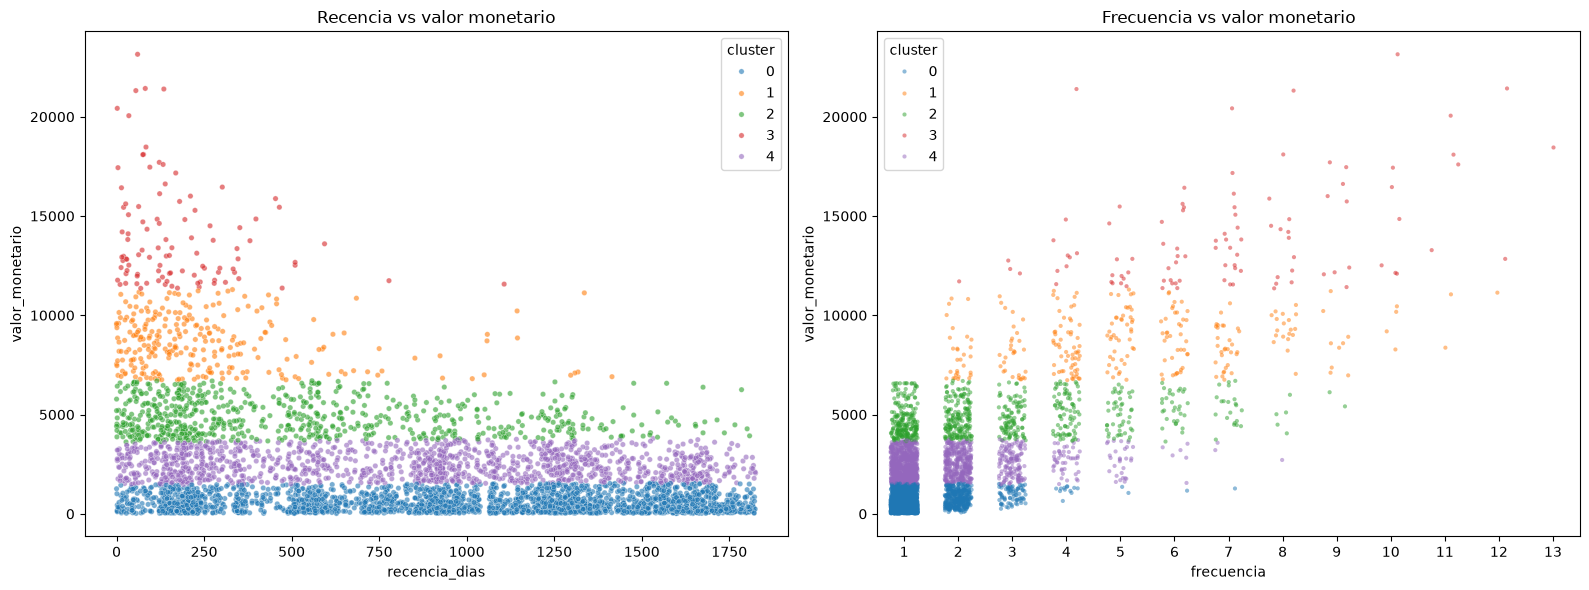

,clientes,gasto_min,gasto_max,recencia_media,frecuencia_media
cluster,,,,,
0,18266,14.1,1554.8,974.4,1.2
1,1916,6730.5,11349.9,258.3,5.0
2,4546,3620.1,6820.4,509.2,2.7
3,604,11356.6,23612.7,167.7,7.1
4,9352,1471.7,3833.3,867.7,1.7


In [51]:
X = rfm[["recencia_dias", "frecuencia", "valor_monetario"]].copy()

# K-Means con k=5 (los segmentos que ya he creado en el RFM)
km_sin = KMeans(n_clusters=5, random_state=42, n_init=10)
rfm["cluster"] = km_sin.fit_predict(X)

# Gráficos
muestra = rfm.sample(5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1  Recencia vs valor monetario
sns.scatterplot(data=muestra, x="recencia_dias", y="valor_monetario",
                hue="cluster", palette="tab10", alpha=0.6, s=15, ax=axes[0])
axes[0].set_title("Recencia vs valor monetario")

# Gráfico 2 Frecuencia vs valor monetario
sns.stripplot(data=muestra, x="frecuencia", y="valor_monetario",
              hue="cluster", palette="tab10", alpha=0.5, size=3,
              jitter=0.25, ax=axes[1])
axes[1].set_title("Frecuencia vs valor monetario")

plt.tight_layout()
plt.show()
 
# Datos de cada cluster
display(rfm.groupby("cluster").agg(
    clientes=("id_cliente", "count"),
    gasto_min=("valor_monetario", "min"),
    gasto_max=("valor_monetario", "max"),
    recencia_media=("recencia_dias", "mean"),
    frecuencia_media=("frecuencia", "mean")
).round(1))

**⚡ Gráfico 1 - recencia vs valor monetario:** Los colores/puntos forman bandas horizontales. Cada banda se extiende por todo el eje horizontal, de 0 a 1.800 días.

**⚡ Gráfico 2 - frecuencia vs valor monetario:** En la columna de 1 compra vemos cinco colores (azul, morado, verde, algo de naranja y casi nada de rojo), ordenados por gasto. Los clientes con el mismo comportamiento, como por ejemplo los de una sola compra, quedan en clusters distintos solo por el importe.

**🚩 Problema:**: los clusters se forman prácticamente solo por valor monetario, e ignora la recencia y la frecuencia, que son las dimensiones que más me interesan para el análisis de recurrencia. Si agrupo por valor monetario, un cliente que compró 5 o veces o un cliente que compró una sola vez se pueden agrupar en el mismo punto, lo mismo con la recencia, y es esto lo que me interesa valorar.

El algoritmo K-Means ha separado los clientes por tramos de gasto. La mayoría de la base de clientes se ha quedado en tres clusters que mezclan clientes recientes y clientes que llevan años sin comprar, así que no me deja ver a quien hay que reactivar o qué clientes se han perdido.

**🎯 COMPROBACIÓN:** En los diferentes grupos la distancía entre la recencia es muy alta, sindo siempre 0 el *min*. Es decir, entrar clientes de todos los segmentos porque solo tiene en cuenta el valor monetario.
Entonces, no se tiene en cuenta el resto de comportamiento del cliente como la frecuencia o recencia. Para seguir avanzando conlos datos es necesario **estandarizarlos**.

In [52]:
# dispersión de recencia dentro de cada cluster
display(rfm.groupby("cluster")["recencia_dias"].agg(["min", "max", "std"]).round(0))

# cómo se reparten los segmentos RFM dentro de cada cluster (en %)
display(pd.crosstab(rfm["cluster"], rfm["segmento"], normalize="index").mul(100).round(1))

,min,max,std
cluster,,,
0,0,1825,524.0
1,0,1729,248.0
2,0,1818,438.0
3,0,1107,143.0
4,0,1825,524.0


segmento,Pasajero Perdido,Primer Vuelo,Turistas en Pausa,Viajero Ocasional,Viajeros Frecuentes
cluster,,,,,
0,49.3,26.7,0.1,23.3,0.6
1,0.6,9.4,0.8,19.2,70.0
2,12.4,32.0,0.9,31.0,23.6
3,0.0,0.8,0.2,3.8,95.2
4,39.7,25.2,0.4,29.3,5.4


**💠 ESTANDARIZAR DATOS**

Necesito que el valor monetario en € no tome tanto peso en el gráfico y a la hora de tenr en cuenta las distancias entre los puntos. Si se mide la distancia de 100 días pero una distancia de 5000€, siempre tendrá mas peso el valor monetario. Por esta razón necesitamos que los datos tengan la misma escala para que ninguna pese más que otra solo por las unidades en las que las estamos midiendo (que son muy diferentes). 


**Z-score** utiliza una fórmula para transformar los datos que tenemos con diferentes tipos de medidas en unas medidas que se asemejen estre si (distribución normal estándar). *Una puntuación z representa el número de desviaciones estándar que un punto de datos se aleja de la media de su distribución*.

        z = (valor − media) / desviación estándar

**🎯 Decisión:** estandarizar mis datos obtenidos en el RFM para que recencia, frecuencia y valor monetario pesen igual.

In [53]:
from sklearn.preprocessing import StandardScaler

# Variables originales (las mismas que usamos en el paso 1)
X = rfm[["recencia_dias", "frecuencia", "valor_monetario"]].copy()

# Estandarización: (valor - media) / desviación estándar, columna por columna
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Lo guardamos como DataFrame para verlo con los nombresultados_kmeans de columna
X_scaled = pd.DataFrame(X_scaled, columns=["recencia_z", "frecuencia_z", "valor_monetario_z"])

# Comprobación 1: medias ~0 y desviaciones 1
print("Medias:")
print(X_scaled.mean().round(2))
print("\n")
print("Desviaciones estándar:")
print(X_scaled.std().round(2))

Medias:
recencia_z          -0.0
frecuencia_z        -0.0
valor_monetario_z   -0.0
dtype: float64


Desviaciones estándar:
recencia_z           1.0
frecuencia_z         1.0
valor_monetario_z    1.0
dtype: float64


• Un valor positivo, como por ejemplo 1.5, significa que ese cliente está por encima de la media del negocio en esa métrica.

• Un valor negativo, como por ejemplo -0.8, significa que ese cliente está por debajo de la media.

• Un valor de 0 significa que es un cliente exactamente promedio.

Ahora, la diferencia no será de 2000€, por ejemplo, ahora todo está en una escala mas cercana y la idea, es que el K-Means haga una mejor agrupación. 

**COMPROBAMOS** la diferencia de los datos con lo que teniamos antes:

In [54]:
# comparar un cliente antes y después
comparacion = pd.concat([X.head(5).reset_index(drop=True), X_scaled.head(5)], axis=1)
display(comparacion.round(2))

,recencia_dias,frecuencia,valor_monetario,recencia_z,frecuencia_z,valor_monetario_z
0,1635,2,363.19,1.47,0.10,-0.71
1,252,4,3324.88,-1.06,1.36,0.36
2,1503,1,109.07,1.23,-0.54,-0.80
3,94,5,4357.10,-1.35,2.00,0.74
4,1498,1,1616.11,1.22,-0.54,-0.25


**💠 K-MEANS CON LOS DATOS ESTANDARIZADOS**

Utilizamos de nuevo el algoritmo de antes K-Means pero con estos datos que tienen valores mas cercanos.

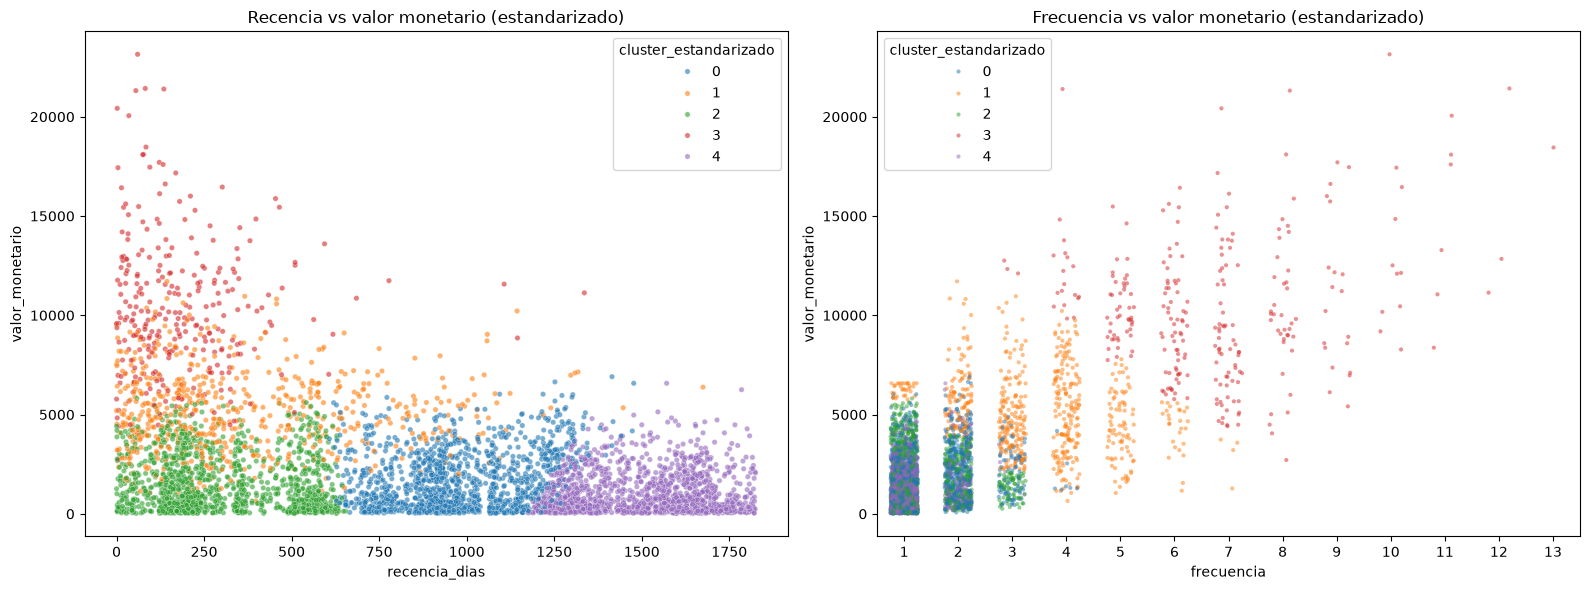

In [55]:
# K-Means con k=5 sobre los datos estandarizados (mismo k que en el paso 1, para comparar)
km_est = KMeans(n_clusters=5, random_state=42, n_init=10) # ejecutarlo 10 veces para que salga lo mejor posible
rfm["cluster_estandarizado"] = km_est.fit_predict(X_scaled)

# Gráficos
muestra = rfm.sample(5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1  Recencia vs valor monetario (igual que antes pero con datos estandarizados)
sns.scatterplot(data=muestra, x="recencia_dias", y="valor_monetario",
                hue="cluster_estandarizado", palette="tab10", alpha=0.6, s=15, ax=axes[0])
axes[0].set_title("Recencia vs valor monetario (estandarizado)")

# Gráfico 2  Frecuencia vs valor monetario (igual que antes pero con datos estandarizados)
sns.stripplot(data=muestra, x="frecuencia", y="valor_monetario",
              hue="cluster_estandarizado", palette="tab10", alpha=0.5, size=3,
              jitter=0.25, ax=axes[1])
axes[1].set_title("Frecuencia vs valor monetario (estandarizado)")

plt.tight_layout()
plt.show()

**⚡ GRÁFICO 1:** Ya no tenemos grupos horizontales que solo tienen en cuenta el valor monetario del clientes. Se forman grupos teniendo en cuenta ambos ejes.

**⚡ GRÁFICO 2:** Ahora el importe no determina la frecuencia. Se mezclan, pero se diferencia aquellos que a mas frecuencia más gasto. Los de poca frecuencia son más dificl de diferenciar, se entremezclan.


**🚩 Problema:** Se mezclan los colores en el gráfico de frecuencia.

In [56]:
# Misma tabla que antes, pero con datos estandarizados
display(rfm.groupby("cluster_estandarizado").agg(
    clientes=("id_cliente", "count"),
    gasto_min=("valor_monetario", "min"),
    gasto_max=("valor_monetario", "max"),
    recencia_media=("recencia_dias", "mean"),
    frecuencia_media=("frecuencia", "mean")
).round(1))

# mezcla con los segmentos RFM
display(pd.crosstab(rfm["cluster_estandarizado"], rfm["segmento"], normalize="index").mul(100).round(1))

rfm.to_csv("RFM_estandarizado.csv")

,clientes,gasto_min,gasto_max,recencia_media,frecuencia_media
cluster_estandarizado,,,,,
0,8960,15.4,6907.8,969.6,1.4
1,4584,364.8,12869.5,357.8,3.4
2,8957,17.4,5814.7,304.5,1.3
3,1881,2064.8,23612.7,177.8,6.7
4,10302,14.1,7298.5,1498.2,1.1


segmento,Pasajero Perdido,Primer Vuelo,Turistas en Pausa,Viajero Ocasional,Viajeros Frecuentes
cluster_estandarizado,,,,,
0,34.0,0.0,0.4,65.6,0.0
1,0.3,19.1,1.5,40.2,38.9
2,0.0,89.2,0.0,10.8,0.0
3,0.0,0.0,0.2,2.9,96.9
4,99.4,0.0,0.0,0.6,0.0


---

Veamos estos datos con el ***método del codo***. Yo he marcado 5 grupos según el RFM pero con el gráfico de frecuencia, se solapana muchos clientes y quiero comprobar si 5 son los grupos correctos

Este método me permite ver cuál es el número de grupos más óptimo según nuestros datos. El punto donde la curva forma un "codo" nos dice cuál puede ser el número ideal de grupos.

,k,inercia,silueta,mejora_inercia_%
0,2,56164.572,0.559,NaN
1,3,34325.363,0.432,38.9
2,4,27204.827,0.417,20.7
3,5,23276.539,0.343,14.4
4,6,20047.637,0.345,13.9
5,7,17830.484,0.354,11.1
6,8,15777.690,0.363,11.5


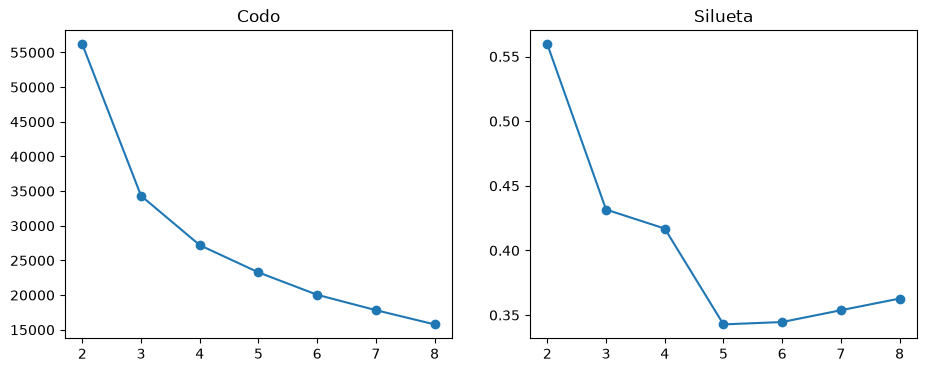

In [57]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados_kmeans = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    resultados_kmeans.append({"k": k,
                "inercia": km.inertia_,
                "silueta": silhouette_score(X_scaled, km.labels_, sample_size=5000, random_state=42)})

resultados_kmeans = pd.DataFrame(resultados_kmeans)
resultados_kmeans["mejora_inercia_%"] = (-resultados_kmeans["inercia"].pct_change() * 100).round(1)
display(resultados_kmeans.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(resultados_kmeans["k"], resultados_kmeans["inercia"], marker="o"); ax[0].set_title("Codo")
ax[1].plot(resultados_kmeans["k"], resultados_kmeans["silueta"], marker="o"); ax[1].set_title("Silueta")
plt.show()

**CODO:** no veo un codo obvio o muy marcado, de 2 a 3 cae bastante pero luego se mantiene bastante estable.  k= 2 sería el número de grupos que nos marca el método.
🚩 2 grupos no serían suficiente ➡ 1 compra / Varias compras. Muy débil para mi proyecto.

**SILUETA:** Aqui puedo ver más diferencia. De 5 a 6 no la hay asi que descarto esa cantidad de grupos. En el RFM puse 5 grupos, pero según estos datos podría dejar 3 o 4. 

**🎯 DECISIÓN GRUPOS:** Finalmente cogeré 4 grupos, porque con 4 grupos obtengo segmentos que el negocio puede interpretar y trabajar, con 3, se mezclarían demasiado el diferente tipo de cliente.

Repito el algortimo K-Means, esta vez le doy 4 grupos /cluster / K para tener la tabla definitiva.

In [58]:
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
rfm["cluster"] = km.labels_

segmentos_finales = {1: "Viajeros de élite", 2: "Viajeros en crecimiento",
           3: "Primer vuelo",   0: "Pasajero perdido"}
rfm["cluster_nombre"] = rfm["cluster"].map(segmentos_finales)

tabla_segmentos_finales = rfm.groupby("cluster_nombre").agg(
    clientes=("id_cliente", "count"),
    recencia=("recencia_dias", "mean"),
    frecuencia=("frecuencia", "mean"),
    gasto=("valor_monetario", "mean"),
    ventas=("valor_monetario", "sum"))

tabla_segmentos_finales["% clientes"] = (tabla_segmentos_finales["clientes"] / tabla_segmentos_finales["clientes"].sum() * 100).round(1)
tabla_segmentos_finales["% ventas"]   = (tabla_segmentos_finales["ventas"]   / tabla_segmentos_finales["ventas"].sum()   * 100).round(1)
display(tabla_segmentos_finales.drop(columns="ventas").round(1).sort_values("gasto", ascending=False))

tabla_segmentos_finales.to_csv("tabla_segmentos_finales.csv")

,clientes,recencia,frecuencia,gasto,% clientes,% ventas
cluster_nombre,,,,,,
Viajeros de élite,2010,178.1,6.7,10002.9,5.8,25.0
Viajeros en crecimiento,5029,399.0,3.2,4931.6,14.5,30.8
Primer vuelo,10527,380.4,1.3,1392.6,30.4,18.2
Pasajero perdido,17118,1311.8,1.2,1222.3,49.4,26.0


### **🎯 CONCLUSIONES** 

+ El 80% de los clientes solo han comprado una vez o hace mucho tiempo que no compran. ¿Por qué?
+ Pero por otro lado, más del 50% de las ventas lo generan solo un 20% de los clientes (de élite o en crecimiento).

---

# ✨ IMPORTANCIA DEL DESCUENTO

## **¿El descuento de la primera compra influye en que el cliente repita?**

🔶 DETERMINAR LA PRIMERA COMPRA DE CADA CLIENTE:

Solo mediré la primera compra porque cada cliente tiene un número de compras diferentes. Si hago una media de todas las compras, el cliente que repite, tiene más compras y por lo tanto cambia el promedio.

In [59]:
reservas["fecha_reserva"] = pd.to_datetime(reservas["fecha_reserva"])

# ordenar cronológicamente
ordenadas = reservas.sort_values(["id_cliente", "fecha_reserva", "id_reserva"])

# numerar las compras de cada cliente: 0 = primera, 1 = segunda...
ordenadas["n_compra"] = ordenadas.groupby("id_cliente").cumcount()

# primera compra con toda su info y fecha de la segunda
primera = ordenadas[ordenadas["n_compra"] == 0].copy()  # solo queremos la primera fila (0) de cada cliente
segunda = (ordenadas[ordenadas["n_compra"] == 1][["id_cliente", "fecha_reserva"]]
           .rename(columns={"fecha_reserva": "fecha_2a_compra"}))

primera = primera.merge(segunda, on="id_cliente", how="left") #añadimos la segunda compra a la tabla, si no hay, queda vacia NaT y nos va a da una alerta
display(primera.head(5))

,fecha_reserva,id_reserva,proveedor,precio_bruto,importe,comision,descuento_real,fecha_salida,fecha_vuelta,numero_noches,...,bebes,destino,pais_destino,categoria_viaje,id_cliente,edad_cliente,sexo_cliente,comunidad_autonoma_cliente,n_compra,fecha_2a_compra
0,2021-06-30,2021-004388,Turismark,383.10,310.31,37.24,19.0,2021-07-19,2021-07-19,12,...,1,Valencia,España,camping,CLT-000001,58,M,Castilla y León,0,2021-07-10
1,2021-07-15,2021-005051,R2 Hoteles,830.98,656.47,78.78,21.0,2021-07-30,2021-07-30,6,...,1,Benidorm,España,solo hotel,CLT-000002,19,F,Navarra,0,2022-07-01
2,2021-11-19,2021-009362,BE Live,126.83,109.07,13.09,14.0,2022-04-06,2022-04-06,1,...,1,Santiago de Compostela,España,solo hotel,CLT-000003,33,M,Comunitat Valenciana,0,NaT
3,2021-06-08,2021-003451,R2 Hoteles,123.98,96.70,11.60,22.0,2021-06-27,2021-06-27,3,...,1,Madrid,España,camping,CLT-000004,26,M,Cataluña,0,2022-01-27
4,2021-11-24,2021-009502,Ohtels,2071.93,1616.11,193.93,22.0,2022-04-11,2022-04-11,13,...,0,Barcelona,España,solo hotel,CLT-000005,61,M,Andalucía,0,NaT


🔶 ¿REPITE O NO REPITE? 

Vamos a ver cuántos clientes de nuestra base de datos han repetido alguna vez en nuestra plataforma. 

In [60]:
# Añadimos una nueva columna, si está vacia (Nat) se quedará en 0 --> no repite
primera["repite"] = primera["fecha_2a_compra"].notna().astype(int)

# contamos los días netre la primera y la segunda reserva (si existe)
primera["dias_hasta_2a"] = (primera["fecha_2a_compra"] - primera["fecha_reserva"]).dt.days

print("Clientes que repiten / no repiten:")
print(primera["repite"].value_counts())

print("\n")
print("¿Cuántos clientes repiten?")
print(round(primera["repite"].mean() * 100, 1), "% de los clientes repite")

print("\n")
print(primera["dias_hasta_2a"].describe().round(0))

Clientes que repiten / no repiten:
repite
0    22042
1    12642
Name: count, dtype: int64


¿Cuántos clientes repiten?
36.4 % de los clientes repite


count    12642.0
mean       251.0
std        181.0
min          1.0
25%         78.0
50%        244.0
75%        379.0
max        756.0
Name: dias_hasta_2a, dtype: float64


⚡El 36,4% de nuestros clientes repiten, no es un porcentaje muy alto, pero tenemos que tener en cuenta que hay clientes que pueden haber comprado en Noviembre de 2025, por ejemplo, y aún no "han tenido tiempo" de repetir. Tengamos en cuenta que lo viajes no se compran habitualmente cada mes.

**📌 Nota importante:**

+ La mitad de quienes repiten lo hacen en unos 8 meses  ➡  mediana (50%) en 244 días	
+ El *máx* de 756 días nos dice que nadie repite pasados 2 años apróx. de la primera compra.


**🚩 Problema:** SI ponemos una ventana de compra de 2 años para analizar la recurrencia de los clientes, quitamos muchos clientes que han comprado el 2024-2025, pero si ponemos solo un año, me quedaré corta con los datos. 



,ventana_dias,%_repeticiones_capturadas,clientes_elegibles,%_clientes_elegibles
0,90,25.5,34120,98.4
1,180,39.2,32557,93.9
2,270,49.1,30245,87.2
3,365,68.7,29225,84.3
4,545,92.2,27419,79.1
5,730,99.4,24823,71.6


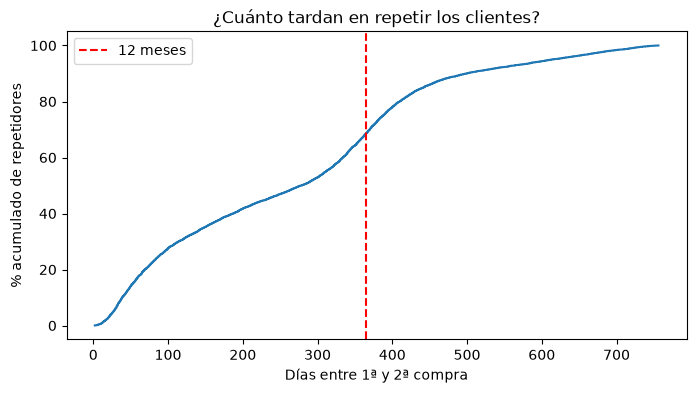

In [61]:
import numpy as np

corte = pd.Timestamp("2025-12-31")

# a ver los clientes que compraron en los 2 primeros años, lo más antiguos (no quiere decir los más fieles)
antiguos = primera[primera["fecha_reserva"] <= "2022-12-31"]
repetidores = antiguos[antiguos["repite"] == 1]

# analizar que ventana de compra (+ 6 meses por periodo), asi podré ver cuál es la que más  conviene para tener un buen número de clientes repetidores
ventanas = [90, 180, 270, 365, 545, 730]  
tabla = pd.DataFrame({
    "ventana_dias": ventanas,
    "%_repeticiones_capturadas": [round((repetidores["dias_hasta_2a"] <= d).mean() * 100, 1) for d in ventanas],
    "clientes_elegibles": [(primera["fecha_reserva"] <= corte - pd.Timedelta(days=d)).sum() for d in ventanas]
})
tabla["%_clientes_elegibles"] = (tabla["clientes_elegibles"] / len(primera) * 100).round(1)
display(tabla)

# GRÁFICO CON CORTE EN LOS 12 MESES Y MAX COMO LA VENTANA QUE NOS DA DE LOS CLIENTES QUE REPITEN
x = repetidores["dias_hasta_2a"].sort_values()
y = np.arange(1, len(x) + 1) / len(x) * 100
plt.figure(figsize=(8, 4))
plt.plot(x, y)
plt.axvline(365, color="red", linestyle="--", label="12 meses")
plt.xlabel("Días entre 1ª y 2ª compra"); plt.ylabel("% acumulado de repetidores")
plt.title("¿Cuánto tardan en repetir los clientes?"); plt.legend()
plt.show()

**🎯 Conclusión:** Según estos datos, lo más lógico sería quedarme con una venta de tiempo de 12 o 18 meses. 

Voy a establecer para seguir con el proyecto que un **cliente es recurrente** si vuelve a comprar en los 18 meses siguientes a su primera compra.

He decidido elegir los 18 meses porque, si miro a los clientes de antiguos de 2021-2022, el 92,2 % de los que repitieron lo hicieron dentro de esos primeros 545 días. 
Si alargo la ventana de recurrencia a 24 meses, no ganaria un % muy alto de repeticiones pero si que perdería muchos clientes y hay muchos que todavía no llevan 24 meses como clientes en la empresa.

In [62]:
VENTANA = 545   #18 meses
corte = pd.Timestamp("2025-12-31")

elegibles = primera[primera["fecha_reserva"] <= corte - pd.Timedelta(days=VENTANA)].copy()
elegibles["repite_18m"] = (elegibles["dias_hasta_2a"] <= VENTANA).astype(int)

print("clientes_elegibles:", len(elegibles), "| excluidos:", len(primera) - len(elegibles))
print(round(elegibles["repite_18m"].mean() * 100, 1), "% repite en 18 meses")
display(pd.crosstab(elegibles["repite"], elegibles["repite_18m"]))

clientes_elegibles: 27419 | excluidos: 7265
37.6 % repite en 18 meses


repite_18m,0,1
repite,,
0,16271,0
1,827,10321


In [63]:
elegibles["descuento_pct"] = elegibles["descuento_real"] * 100

resumen_18m = (elegibles.groupby("repite_18m")["descuento_pct"]
           .agg(clientes="count", media="mean", mediana="median", desv="std")
           .round(2))
display(resumen_18m)

,clientes,media,mediana,desv
repite_18m,,,,
0,17098,1753.98,1800.0,434.89
1,10321,1750.94,1800.0,432.16


In [64]:
elegibles["descuento_pct"] = elegibles["descuento_pct"] / 100

In [65]:
elegibles["tramo"] = pd.cut(elegibles["descuento_pct"],
                            bins=[9.99, 13, 16, 19, 22, 25.01],
                            labels=["10-13%", "13-16%", "16-19%", "19-22%", "22-25%"])
tabla_tramos_pct = (elegibles.groupby("tramo", observed=True)["repite_18m"]
         .agg(clientes="count", pct_repite=lambda s: round(s.mean() * 100, 1)))
display(tabla_tramos_pct)


tabla_tramos_pct.to_csv("tabla_tramos_pct.csv")

,clientes,pct_repite
tramo,,
10-13%,6297,37.7
13-16%,5505,36.8
16-19%,5596,39.6
19-22%,5422,36.7
22-25%,4599,37.2


**🎯 Conclusión:**  Como el porcentaje de descuento no varía mucho, no hay una tendencia clara de clientes que repiten si es descuento es mayor o menor. El porcentaje es bastante estable. 

El tramo de 16%-19% resalta un poquito pero no los sufciente como para decir que el porcentaje de la primera venta SI afecta a la fidelización o repetición del cliente a la hora de comprar.

---